In [65]:
import kagglehub
path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.


In [81]:
import pandas as pd
import numpy as np
from nltk.stem import PorterStemmer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, GRU
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

In [82]:
df = pd.read_csv(path + '/IMDB Dataset.csv')
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
df.shape

(50000, 2)

**Data preprocessing**

In [83]:
df.isnull().sum()

,0
review,0
sentiment,0


In [84]:
df.value_counts('sentiment')

,count
sentiment,
negative,25000
positive,25000


In [85]:
df.duplicated().sum()

np.int64(418)

In [86]:
df.drop_duplicates(inplace=True)

In [87]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [88]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))
def clean_text(text):
    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # Remove special characters, numbers, and punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text, re.I | re.A)
    # Convert to lowercase
    text = text.lower()
    #stamming
    words = text.split()
    stemmed_words = [stemmer.stem(word) for word in words]
    #remove stopwords
    removed_stop_words = [word for word in stemmed_words if word not in stop_words]

    # Join the words
    text = ' '.join(removed_stop_words)
    return text

In [89]:
df['cleaned_review'] = df['review'].apply(clean_text)

/tmp/ipykernel_4193/3997557911.py:7: DeprecationWarning: 'count' is passed as positional argument
  text = re.sub(r'[^a-zA-Z\s]', '', text, re.I | re.A)


In [72]:
df.head()

,review,sentiment,cleaned_review
0,One of the other reviewers has mentioned that ...,positive,one review ha mention watch oz episod youll ho...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product film techniqu veri unassu...
2,I thought this was a wonderful way to spend ti...,positive,thought thi wa wonder way spend time hot summe...
3,Basically there's a family where a little boy ...,negative,basic famili littl boy jake think zombi hi clo...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei love time money visual stun film...


In [73]:
cleaned_df = df.drop('review', axis=1)


In [74]:
le = LabelEncoder()
cleaned_df['sentiment'] = le.fit_transform(cleaned_df['sentiment'])

In [75]:
cleaned_df.head()

,sentiment,cleaned_review
0,1,one review ha mention watch oz episod youll ho...
1,1,wonder littl product film techniqu veri unassu...
2,1,thought thi wa wonder way spend time hot summe...
3,0,basic famili littl boy jake think zombi hi clo...
4,1,petter mattei love time money visual stun film...


In [ ]:
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(cleaned_df['cleaned_review']).toarray()
y = cleaned_df['sentiment'].values

print("Shape of feature matrix X:", X.shape)
print("Shape of target labels y:", y.shape)

Shape of feature matrix X: (49582, 5000)
Shape of target labels y: (49582,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (39665, 5000)
Testing set shape: (9917, 5000)


**Model Training**

Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

#
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8801048704245236

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.86      0.88      4939
           1       0.87      0.90      0.88      4978

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917



XGBoost

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier()
xgb_model.fit(X_train, y_train)

# Predict and evaluate
y_pred_xgb = xgb_model.predict(X_test)
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))

XGBoost Accuracy: 0.8504588081072905

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.82      0.85      4939
           1       0.83      0.88      0.86      4978

    accuracy                           0.85      9917
   macro avg       0.85      0.85      0.85      9917
weighted avg       0.85      0.85      0.85      9917



LSTM

In [76]:
max_words = 20000
max_len = 200

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(cleaned_df['cleaned_review'])

X_seq = tokenizer.texts_to_sequences(cleaned_df['cleaned_review'])
X_pad = pad_sequences(X_seq, maxlen=max_len, padding='post', truncating='post')

y = cleaned_df['sentiment'].values

X_train, X_test, y_train, y_test = train_test_split(X_pad, y, test_size=0.2, random_state=42)


#Build the LSTM Model
model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    Bidirectional(LSTM(32, return_sequences=False)),
    Dropout(0.3),
    Dense(64, activation='relu',kernel_regularizer=l2(0.001)),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])
model.compile(
    loss='binary_crossentropy',
    optimizer= Adam(learning_rate=0.0005),
    metrics=['accuracy']
    )


In [77]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=1,
    restore_best_weights=True
    )
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    min_lr=1e-5
)

# 4. Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    validation_data=(X_test, y_test),
    callbacks = [early_stopping, reduce_lr]
    )

Epoch 1/20
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 28s 21ms/step - accuracy: 0.8291 - loss: 0.4065 - val_accuracy: 0.8785 - val_loss: 0.3154 - learning_rate: 5.0000e-04
Epoch 2/20
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.9171 - loss: 0.2369 - val_accuracy: 0.8812 - val_loss: 0.3093 - learning_rate: 5.0000e-04
Epoch 3/20
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 26s 21ms/step - accuracy: 0.9400 - loss: 0.1760 - val_accuracy: 0.8780 - val_loss: 0.3312 - learning_rate: 5.0000e-04


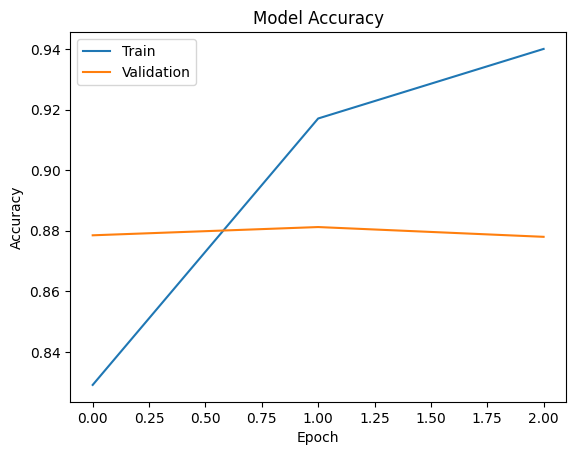

In [78]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()


Prediction Using LSTM

In [79]:
def predict_sentiment(reviews):
    # Preprocess the input reviews using your existing clean_text function
    cleaned_reviews = [clean_text(review) for review in reviews]

    # Convert text to sequences
    seqs = tokenizer.texts_to_sequences(cleaned_reviews)

    # Pad sequences
    padded_seqs = pad_sequences(seqs, maxlen=max_len, padding='post', truncating='post')

    # model predictions
    predictions = model.predict(padded_seqs)

    # Convert probabilities to binary labels and readable text
    results = []
    for pred in predictions:
        score = float(pred[0])
        sentiment = "Positive" if score >= 0.5 else "Negative"
        results.append({"score": score, "sentiment": sentiment})

    return results

# Example query data to test
query_reviews = [
    "This movie was an absolute masterpiece! The acting and storyline were phenomenal.",
    "Terrible waste of time. The plot made no sense and the acting was awful."
]

# Run predictions
predictions = predict_sentiment(query_reviews)
for q, res in zip(query_reviews, predictions):
    print(f"Review: {q}")
    print(f"Prediction: {res['sentiment']} (Confidence Score: {res['score']:.4f})\n")

/tmp/ipykernel_4193/3997557911.py:7: DeprecationWarning: 'count' is passed as positional argument
  text = re.sub(r'[^a-zA-Z\s]', '', text, re.I | re.A)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
Review: This movie was an absolute masterpiece! The acting and storyline were phenomenal.
Prediction: Positive (Confidence Score: 0.7433)

Review: Terrible waste of time. The plot made no sense and the acting was awful.
Prediction: Negative (Confidence Score: 0.0085)



In [80]:
# Predict probabilities on the test set
y_pred_probs = model.predict(X_test)

# Convert probabilities to binary class labels
y_pred_lstm = (y_pred_probs >= 0.5).astype(int).flatten()

# Evaluate the LSTM model
print("LSTM Accuracy:", accuracy_score(y_test, y_pred_lstm))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lstm))

310/310 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step
LSTM Accuracy: 0.8812140768377533

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.85      0.88      4939
           1       0.86      0.92      0.89      4978

    accuracy                           0.88      9917
   macro avg       0.88      0.88      0.88      9917
weighted avg       0.88      0.88      0.88      9917

